# B20 怎样训练一个评论情感分类器？

任务：用一份可检查的小型英文评论语料比较 TF-IDF 线性模型和词向量平均网络；中文解释帮助你观察分词、词表和否定句错误。

先修：B08 文本向量与 B16 训练；补充词表、未知词、padding 掩码。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 先写清语料和划分
此语料由课程作者编写，不是真实用户数据。训练和测试句子分别列出，测试包含否定、同义改写和混合评价。很小的语料只能学习流程，不能给出产品质量结论。

In [2]:
import json
import time
import numpy as np
started = time.perf_counter()
def finish(metrics):
    metrics["elapsed_seconds"] = round(time.perf_counter() - started, 3)
    (OUT_DIR / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2))
def barplot(labels, values, title, filename="comparison.png"):
    fig, ax = plt.subplots()
    ax.bar(labels, values)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(OUT_DIR / filename)
    plt.close(fig)

import re
import torch
from torch import nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
torch.set_num_threads(2)
torch.manual_seed(20)
positive = ['great food and friendly service', 'excellent quality and fast delivery', 'I love this useful product', 'wonderful experience with helpful staff', 'good value and reliable design', 'the room was clean and comfortable', 'very happy with the purchase', 'delicious meal and nice atmosphere', 'works perfectly and feels sturdy', 'amazing support solved my problem', 'easy to use and good performance', 'I recommend this excellent book']
negative = ['terrible food and rude service', 'poor quality and slow delivery', 'I hate this useless product', 'awful experience with unhelpful staff', 'bad value and unreliable design', 'the room was dirty and uncomfortable', 'very unhappy with the purchase', 'disgusting meal and noisy atmosphere', 'does not work and feels fragile', 'horrible support ignored my problem', 'hard to use and bad performance', 'I regret buying this boring book']
texts = positive + negative
labels = np.array([1] * len(positive) + [0] * len(negative))
test_texts = ['friendly staff and excellent food', 'slow delivery and terrible quality', 'good product with reliable performance', 'rude staff and dirty room', 'not good at all', 'not a terrible experience', 'helpful support but slow delivery', 'I love the clean comfortable room']
test_labels = np.array([1, 0, 1, 0, 0, 1, 0, 1])
(DATA_DIR / 'reviews.json').write_text(json.dumps({'train': list(zip(texts, labels.tolist())), 'test': list(zip(test_texts, test_labels.tolist()))}, ensure_ascii=False, indent=2), encoding='utf-8')

2034

## 2. TF-IDF 基线与只来自训练集的词表
词表把 token 映射到整数，0 是补齐、1 是未知词。不能先用测试语料建立词表。TF-IDF 使用一元和二元词组，给否定搭配保留一些表达空间。

In [3]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2))
baseline = LogisticRegression(C=2, max_iter=300).fit(vectorizer.fit_transform(texts), labels)

def tokenize(text):
    return re.findall('[a-z]+', text.lower())
vocab = {'<pad>': 0, '<unk>': 1}
for text in texts:
    for token in tokenize(text):
        if token not in vocab:
            vocab[token] = len(vocab)

def encode(sentences, max_len=16):
    result = np.zeros((len(sentences), max_len), dtype='int64')
    for i, text in enumerate(sentences):
        ids = [vocab.get(word, 1) for word in tokenize(text)[:max_len]]
        result[i, :len(ids)] = ids
    return torch.tensor(result)
assert encode(['unseenword'])[0, 0].item() == 1

## 3. Embedding 加掩码平均
Embedding 将编号变成 24 维可学习向量。mask 排除 padding，分母 clamp 防止空句除零。平均池化会丢失顺序，所以这是一个特意简单、有明确局限的网络。交叉熵的类别标签使用 torch.long，保持与损失函数的类型约定一致。

In [4]:
class SentimentNet(nn.Module):

    def __init__(self, size):
        super().__init__()
        self.embedding = nn.Embedding(size, 24, padding_idx=0)
        self.head = nn.Linear(24, 2)

    def forward(self, ids):
        mask = (ids != 0).unsqueeze(-1)
        pooled = (self.embedding(ids) * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.head(pooled)
network = SentimentNet(len(vocab))
opt = torch.optim.Adam(network.parameters(), lr=0.025)
train_ids = encode(texts)
train_labels = torch.tensor(labels, dtype=torch.long)
losses = []
for epoch in range(70):
    opt.zero_grad()
    loss = nn.CrossEntropyLoss()(network(train_ids), train_labels)
    loss.backward()
    opt.step()
    losses.append(float(loss.detach()))

## 4. 保存逐条预测和失败类型
输出两种预测以便人工检查“not good”等否定句。准确率只是这八句上的描述统计，不能当总体保证；复杂模型在小数据上很可能过拟合。

In [5]:
network.eval()
with torch.no_grad():
    neural_pred = network(encode(test_texts)).argmax(1).numpy()
linear_pred = baseline.predict(vectorizer.transform(test_texts))
rows = [{'text': t, 'label': int(y), 'tfidf': int(a), 'embedding': int(b)} for t, y, a, b in zip(test_texts, test_labels, linear_pred, neural_pred)]
(OUT_DIR / 'predictions.json').write_text(json.dumps(rows, ensure_ascii=False, indent=2), encoding='utf-8')
scores = [float(accuracy_score(test_labels, linear_pred)), float(accuracy_score(test_labels, neural_pred))]
barplot(['TF-IDF', 'Embedding 平均'], scores, '小语料独立测试准确率')
finish({'tfidf_accuracy': scores[0], 'embedding_accuracy': scores[1], 'test_samples': len(test_labels), 'vocabulary_size': len(vocab), 'training_loss': losses[-1]})

{
  "tfidf_accuracy": 0.75,
  "embedding_accuracy": 0.625,
  "test_samples": 8,
  "vocabulary_size": 77,
  "training_loss": 0.00035102423862554133,
  "elapsed_seconds": 8.085
}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

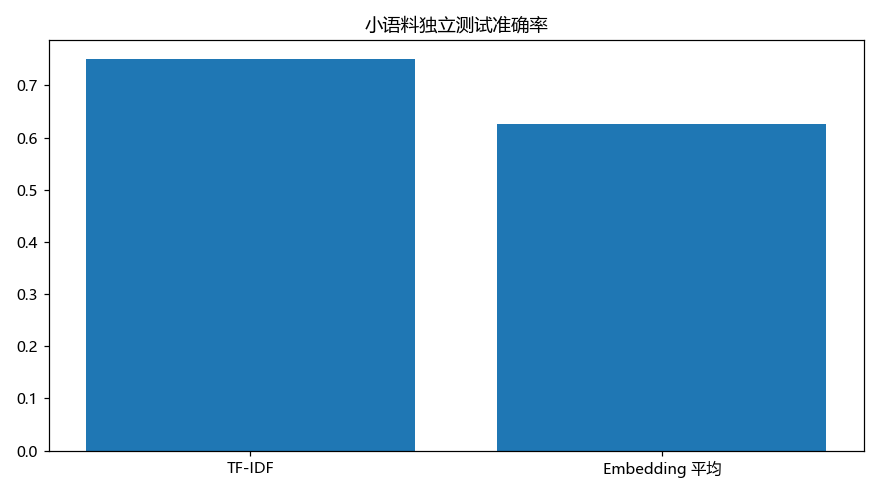

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
混合评价的标签依赖任务定义；本例将物流差的混合评价标负面，必须在真实任务中和业务方约定。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。